## 02 · Manifold — principal curve + pseudotime

Gate 1 was GO. Here we score the three embryonic modules (Gast / pSom / Crest) with the
union control pool, check **biology before geometry** (do Gast/pSom co-vary or diverge? is
cycling a confound?), fit the scFates trajectory whose topology **matches the data**, root it
at the developmental origin (Gast/pSom-high — neural crest is *late*, never the root), and
verify the curve is fold-free.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load processed manifold; confirm it is an elongated (linear) cloud, not two blobs
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
adata

whole malignant manifold: 2118 cells
UMAP aspect ratio (major/minor std): 1.83


In [4]:
# score the three embryonic modules (union control pool) + graph-smooth for geography.
# smoothing (knn-connectivity averaging) AIDS the geography read; deliverable UMAPs in 03
# show the RAW scores per the binding rule.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present


In [5]:
# biology before geometry: one axis or two competing arms? is cycling a confound?
print('smoothed spatial correlations (whole manifold):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]; print(f'  {a} vs {b}: r = {r:+.2f}')
cyc = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
print('proliferation confound (Spearman module vs g2m_score):')
for m in ['Gast', 'pSom', 'Crest']:
    rho, _ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs g2m: rho = {rho:+.2f}')
print('-> Gast/pSom CO-VARY (r>0); both OPPOSE Crest; no module tracks proliferation.')
print('   single embryonic axis (no competing arms) -> non-branching. Keep the whole manifold.')

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.56
  Crest_sm vs Gast_sm: r = -0.87
  Crest_sm vs pSom_sm: r = -0.57
proliferation confound (Spearman module vs g2m_score):
  Gast vs g2m: rho = +0.01
  pSom vs g2m: rho = +0.12
  Crest vs g2m: rho = -0.02
-> Gast/pSom CO-VARY (r>0); both OPPOSE Crest; no module tracks proliferation.
   single embryonic axis (no competing arms) -> non-branching. Keep the whole manifold.


In [6]:
# topology test: a branching TREE vs a non-branching CURVE.
# a clean bifurcation would give a tree with ONE fork + 3 tips; noise gives many.
def _diag_tree(ad):
    B = np.asarray(ad.uns['graph']['B'])
    return int(((B > 0).sum(0) == 1).sum()), int(((B > 0).sum(0) >= 3).sum())
print('TREE fit (branching hypothesis):')
for Nodes in [30, 50]:
    ad2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad2, method='ppt', Nodes=Nodes, ppt_lambda=100, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    t, f = _diag_tree(ad2); print(f'  Nodes={Nodes}: {t} tips, {f} forks')
print('-> many tips/forks = no clean single bifurcation; the tree over-fits noise.')

TREE fit (branching hypothesis):
  Nodes=30: 8 tips, 6 forks
  Nodes=50: 9 tips, 7 forks
-> many tips/forks = no clean single bifurcation; the tree over-fits noise.


In [7]:
# fit the principal CURVE (non-branching) + fold diagnostic.
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free 2-tip curve)'
print('robust: 2 tips / 0 forks, no fold -> non-branching curve confirmed')

curve: 2 tips, 0 forks | self-approach ratio = 2.96 (>1 = fold-free)
robust: 2 tips / 0 forks, no fold -> non-branching curve confirmed


In [8]:
# root at the developmental origin: the Gast/pSom-high, Crest-low tip (Crest is LATE).
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.3f} pSom={info[tp][1]:+.3f} Crest={info[tp][2]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, p = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}  p = {p:.1e}')

tip 0: Gast=-0.037 pSom=+0.199 Crest=+0.177
tip 2: Gast=+0.043 pSom=+0.213 Crest=+0.060
derived root = tip 2 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.731  p = 0.0e+00
  pSom_sm: rho = -0.142  p = 4.9e-11
  Crest_sm: rho = +0.759  p = 0.0e+00


milestones: {'0': 'Crest terminus', '2': 'Gast/pSom origin'}


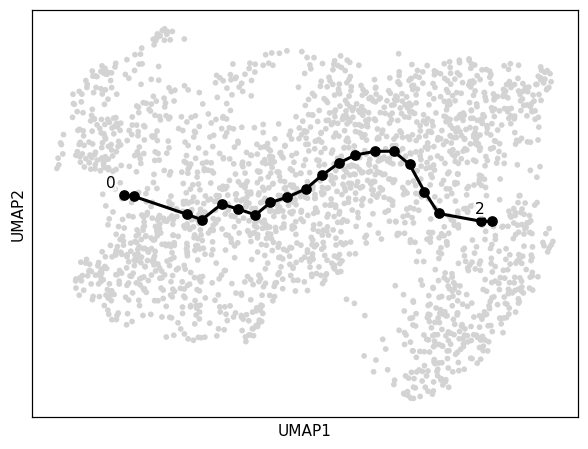

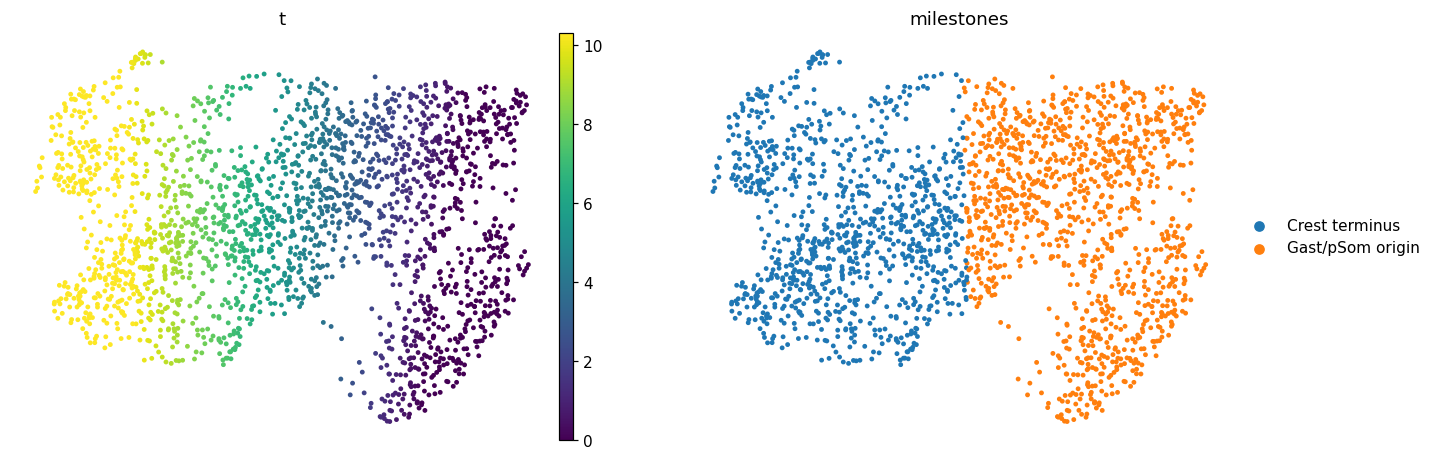

In [9]:
# rename milestones (root / terminus) + visual inspection (pseudotime + curve edges)
adata.obs['milestones'] = adata.obs['milestones'].astype('category')
ms = adata.obs['milestones'].cat.categories.tolist()
tmean = {m: adata.obs.loc[adata.obs['milestones'] == m, 't'].mean() for m in ms}
newnames = {m: ('Gast/pSom origin' if tmean[m] == min(tmean.values()) else 'Crest terminus') for m in ms}
scf.tl.rename_milestones(adata, new=newnames)
print('milestones:', newnames)
scf.pl.graph(adata, basis='umap')                       # curve WITH EDGES (fold check)
sc.pl.umap(adata, color=['t', 'milestones'], size=40, frameon=False)

In [10]:
# orientation consistency: reuse the house X_umap_lin from 01, verify vs pseudotime
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:, 0], adata.obs['t'].values)[0, 1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:
    adata.obsm['X_umap_lin'][:, 0] = -adata.obsm['X_umap_lin'][:, 0]; r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99


In [11]:
# sanitize non-serializable ElPiGraph uns entry, then save manifold
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (2118, 21106)


saved manifold.pdf


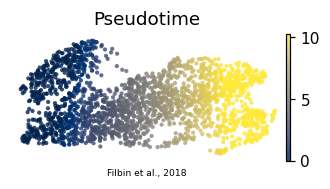

In [12]:
# deliverable: manifold.pdf -- pseudotime on the house linear layout (3.5,1.5)
xl = adata.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')